# PLATE WITH A CENTRAL HOLE - STATIC STRUCTURE ANALYSIS FEA

Problem : There is 200 x 100 x 2 mm stainless-steel plate with a 20mm diameter central hole, one end is fixed and other end is pulled outwords with 40MP.
Keep mesh size 2 mm,
To Find = von miss stress and Factor of safety

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Delaunay
from skfem import MeshTri, Basis, FacetBasis, ElementTriP2, ElementVector, BilinearForm, LinearForm, condense, solve
from skfem.helpers import sym_grad, ddot, eye, trace

# GEOMETRIC PARAMETERS AND MATERIAL SELECTION

In [2]:
# GEOMETRY

L = 200.0  #LENGTH OF THE PLATE
W = 100.0  #WIDTH OF THE PLATE
T = 2.0    #THICKNESS OF THE PLATE
D = 20.0   #DIAMETER OF THE HOLE
R = D/2.0  #RADIUS OF THE HOLE
#ALL DIMENSIONS ARE IN MM

#MATERIAL PROPERTIES OF STAINLESS STEEL

E = 193E3    #YOUNG'S MODULUS (MPA)
nu = 0.3     #POISSON'S RATIO
SY = 207.0   #YIELD STRENGTH (MPA)

# LOADING 
P = 40.0     #APPLIED LOAD (MPA)
mesh_size =1.0 #mm

Points are placed on outer boundary, around hole and in interior, then triangulated.
Triangles inside the hole were removed.
quad elements are used for displacement field

Transforming over 1000 vertices to C_CONTIGUOUS.
Transforming over 1000 elements to C_CONTIGUOUS.


Nodes: 22935, Elements: 45207


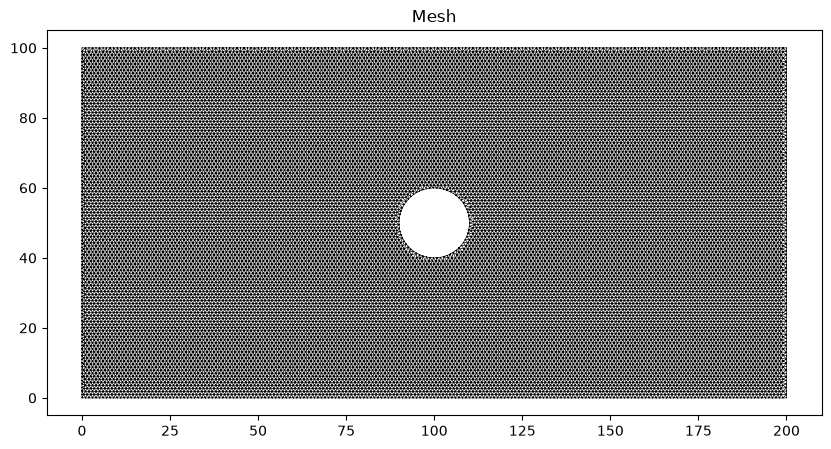

In [3]:
h = mesh_size
#outer boundary points
bx = np.arange(0,L+1e-9,h)
by = np.arange(0,W+1e-9,h)
outer = np.vstack([
    np.c_[bx, np.zeros_like(bx)],                 # bottom edge  (y = 0)
    np.c_[bx, np.full_like(bx, W)],               # top edge     (y = W)
    np.c_[np.zeros_like(by[1:-1]), by[1:-1]],     # left edge    (x = 0)
    np.c_[np.full_like(by[1:-1], L), by[1:-1]]    # right edge   (x = L)
])

#hole boundary points
n_hole = int(round(2*np.pi*R/h))
th = np.linspace(0,2*np.pi,n_hole,endpoint=False)
cx, cy = L/2, W/2
hole = np.c_[cx+ R*np.cos(th), cy+R*np.sin(th)]
pts=[]
for j, y in enumerate(np.arange(h,W-h/2,h*np.sqrt(3)/2)):
    off = (h/2)*(j%2)
    for x in np.arange(h/2+off,L-h/2,h):
        if np.hypot(x-cx, y-cy) > R + 0.7*h and h*0.7 < y < W - h*0.7: # type: ignore
            pts.append((x,y))
points = np.vstack([outer, hole, np.array(pts)])

tri = Delaunay(points)
cent = points[tri.simplices].mean(axis=1)
keep = np.hypot(cent[:,0]-cx, cent[:,1]-cy)>R
mesh = MeshTri(points.T, tri.simplices[keep].T)
print(f"Nodes: {mesh.p.shape[1]}, Elements: {mesh.t.shape[1]}")

plt.figure(figsize=(10, 5)); mesh.draw(ax=plt.gca()); plt.title("Mesh"); plt.show()

# MATERIAL ASSIGN, BOUNDARY AND LOADING CONDITIONS

In [4]:
basis = Basis(mesh, ElementVector(ElementTriP2()), intorder=3)

lam = E*nu/(1-nu**2)
mu = E/(2*(1+nu))

@BilinearForm
def stiffness(u,v,w):
    eu, ev = sym_grad(u), sym_grad(v)
    return  T *(2*mu*ddot(eu,ev)+lam*trace(eu)*trace(ev))
K = stiffness.assemble(basis)

right= mesh.facets_satisfying(lambda x : np.isclose(x[0],L))
fbasis = FacetBasis(mesh,basis.elem, facets=right)

@LinearForm
def load(v,w):
    return T*P*v.value[0]
f = load.assemble(fbasis)

left = mesh.facets_satisfying(lambda x : np.isclose(x[0],0))
fixed_dofs = basis.get_dofs(left)

u = solve(*condense(K,f,D=fixed_dofs))
ux, uy = u[basis.nodal_dofs[0]], u[basis.nodal_dofs[1]]

print(f"Max displacement magnitude: {np.max(np.hypot(ux, uy)):.4f} mm")
print(f"Total applied force: {T*P:.1f} N | Sum of reaction check: {f.sum():.1f} N")

Max displacement magnitude: 0.0434 mm
Total applied force: 80.0 N | Sum of reaction check: 8000.0 N


# STRESS ANALYSIS AND FOS

In [5]:
g = basis.interpolate(u).grad                  # shape (2, 2, n_elem, n_qp)
exx, eyy, exy = g[0,0], g[1,1], 0.5*(g[0,1] + g[1,0])
c = E/(1 - nu**2)
sxx = c*(exx + nu*eyy)
syy = c*(eyy + nu*exx)
sxy = E/(2*(1 + nu))*2*exy
vm  = np.sqrt(sxx**2 - sxx*syy + syy**2 + 3*sxy**2)    # von Mises  [MPa]

max_vm = vm.max()
FoS = SY / max_vm
print(f"Maximum von Mises stress : {max_vm:.2f} MPa")
print(f"Maximum principal stress : {(0.5*(sxx+syy) + np.sqrt((0.5*(sxx-syy))**2 + sxy**2)).max():.2f} MPa")
print(f"Safety factor (SY/sigma_max) : {FoS:.2f}")

Maximum von Mises stress : 121.72 MPa
Maximum principal stress : 122.74 MPa
Safety factor (SY/sigma_max) : 1.70


Text(0.5, 1.0, 'von Mises stress distribution (max = 121.72 MPa, FoS = 1.70)')

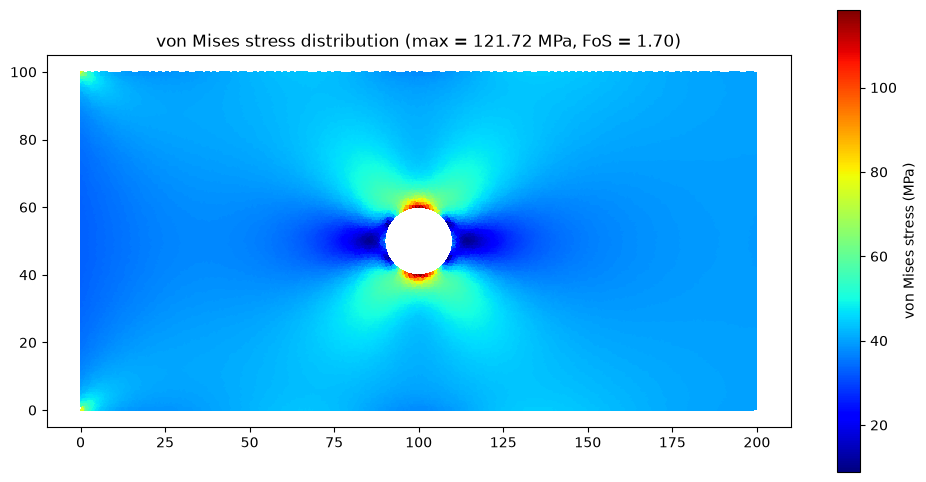

In [6]:
elem_vm = vm.mean(axis=1)
import matplotlib.tri as mtri
triang = mtri.Triangulation(mesh.p[0],mesh.p[1], mesh.t.T)
fig, ax = plt.subplots(figsize=(12,6))
tpc = ax.tripcolor(triang, facecolors=elem_vm, cmap="jet")
fig.colorbar(tpc, ax=ax, label='von Mises stress (MPa)')
ax.set_aspect('equal')
ax.set_title(f'von Mises stress distribution (max = {max_vm:.2f} MPa, FoS = {FoS:.2f})')